#### Create a simple machine learning pipeline using a dataset of your choice. This pipeline
#### should include data loading, a basic exploratory data analysis, model training using a decision
#### tree classifier, and model validation (using train-test split).
Deliverables:

● A Jupyter notebook containing the code and brief comments explaining each step.

● A summary report discussing the choice of model, the model’s performance, and
potential ways to improve it.

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

##### Loading the cleaned laptop prices dataset
##### Since i will be using decision tress and laptop prices is a continuous target (Price), I will be converting prices into categories (Low, Medium, High, Very High) to make this valid classification problem.

In [2]:
laptops = pd.read_csv(r"C:\Users\BerniceBoateng\Desktop\machine-learning-zoomcamp\cleaned_laptop_data.csv")
laptops.head(3)

,company,typename,inches,ram,weight,price,screen_type,screen_width,screen_height,touchscreen,cpu_name,cpu_brand,cpu_speed,hdd,ssd,hybrid,flash_storage,gpu_brand,operating_system
0,apple,ultrabook,13.3,8,1.37,71378.6832,ips panel retina display,2560,1600,0,intel core i5,intel core i5,2.3,0,128,0,0,intel iris,mac
1,apple,ultrabook,13.3,8,1.34,47895.5232,standard,1440,900,0,intel core i5,intel core i5,1.8,0,0,0,128,intel hd,mac
2,hp,notebook,15.6,8,1.86,30636.0000,full hd,1920,1080,0,intel core i5,intel core i5,2.5,0,256,0,0,intel hd,others/no os


In [3]:
laptops.shape

(1244, 19)

##### Exploratory Data Analysis

In [4]:
# checking for missing values
print(laptops.isnull().sum())

company             0
typename            0
inches              0
ram                 0
weight              0
price               0
screen_type         0
screen_width        0
screen_height       0
touchscreen         0
cpu_name            0
cpu_brand           0
cpu_speed           0
hdd                 0
ssd                 0
hybrid              0
flash_storage       0
gpu_brand           0
operating_system    0
dtype: int64


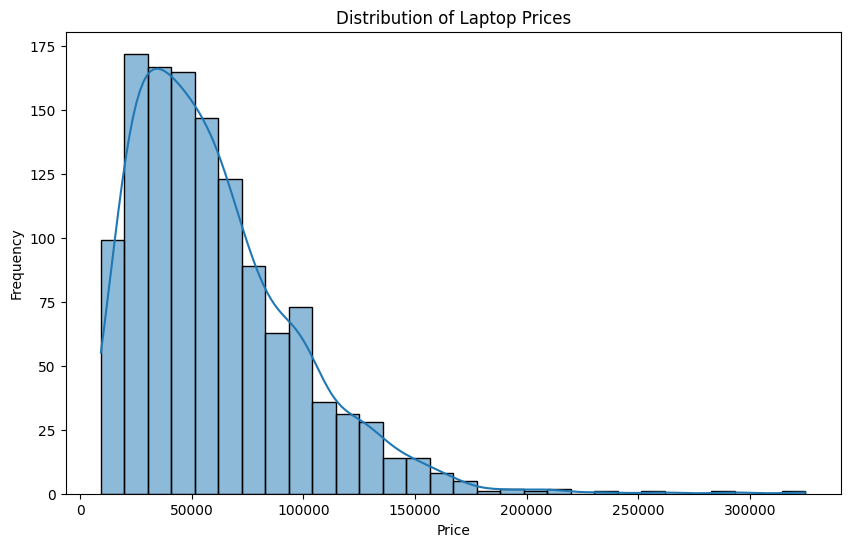

In [5]:
# visulaizing the price distribution
plt.figure(figsize=(10, 6))
sns.histplot(laptops['price'], bins=30, kde=True)
plt.title('Distribution of Laptop Prices')
plt.xlabel('Price')
plt.ylabel('Frequency')
plt.show()

In [6]:
# summary for the price of the laptop
print(laptops['price'].describe())

count      1244.000000
mean      60606.224427
std       37424.636161
min        9270.720000
25%       32655.445200
50%       52693.920000
75%       79813.440000
max      324954.720000
Name: price, dtype: float64


#### Data Preprocessing

In [7]:
# converting prices into 4 categories (low, medium, high, very high)
# using qcut to split the prices into 4 quartiles
laptops['price_category'] = pd.qcut(laptops['price'], q=4, labels=['Low', 'Medium', 'High', 'Very High'])
print(laptops['price_category'].value_counts())

price_category
Medium       312
Low          311
High         311
Very High    310
Name: count, dtype: int64


In [8]:
laptops.head(3)

,company,typename,inches,ram,weight,price,screen_type,screen_width,screen_height,touchscreen,cpu_name,cpu_brand,cpu_speed,hdd,ssd,hybrid,flash_storage,gpu_brand,operating_system,price_category
0,apple,ultrabook,13.3,8,1.37,71378.6832,ips panel retina display,2560,1600,0,intel core i5,intel core i5,2.3,0,128,0,0,intel iris,mac,High
1,apple,ultrabook,13.3,8,1.34,47895.5232,standard,1440,900,0,intel core i5,intel core i5,1.8,0,0,0,128,intel hd,mac,Medium
2,hp,notebook,15.6,8,1.86,30636.0000,full hd,1920,1080,0,intel core i5,intel core i5,2.5,0,256,0,0,intel hd,others/no os,Low


In [9]:
categorical_columns = laptops.select_dtypes(include=['object']).columns
print("categorical columns selected:", list(categorical_columns))



categorical columns selected: ['company', 'typename', 'screen_type', 'cpu_name', 'cpu_brand', 'gpu_brand', 'operating_system']


In [10]:
# applying one hot encoding
laptops_encoded = pd.get_dummies(laptops, columns=categorical_columns, drop_first=True) 
laptops_encoded.head(3)

,inches,ram,weight,price,screen_width,screen_height,touchscreen,cpu_speed,hdd,ssd,...,gpu_brand_intel graphics,gpu_brand_intel hd,gpu_brand_intel iris,gpu_brand_intel uhd,gpu_brand_nvidia geforce,gpu_brand_nvidia gtx,gpu_brand_nvidia quadro,operating_system_mac,operating_system_others/no os,operating_system_windows
0,13.3,8,1.37,71378.6832,2560,1600,0,2.3,0,128,...,False,False,True,False,False,False,False,True,False,False
1,13.3,8,1.34,47895.5232,1440,900,0,1.8,0,0,...,False,True,False,False,False,False,False,True,False,False
2,15.6,8,1.86,30636.0000,1920,1080,0,2.5,0,256,...,False,True,False,False,False,False,False,False,True,False


#### Model training

#### DECISION TREE CLASSIFIER

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

In [12]:
# defining my x which is the input and y which is the target
x = laptops_encoded.drop(['price', 'price_category'], axis=1)
y = laptops_encoded['price_category']

In [13]:
# splitting the data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)   

In [14]:
# training the model
model = DecisionTreeClassifier()
model.fit(x_train, y_train)
print("Model training completed.")

Model training completed.


#### Testing models accuracy

In [15]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import joblib

In [16]:
# making predictions on the test set
y_pred = model.predict(x_test)

In [17]:
# evaluating performance
accuracy = accuracy_score(y_test, y_pred)
conf_matrix = confusion_matrix(y_test, y_pred)
print(f"Models Accuracy: {accuracy * 100:.2f}%")
print("\nConfusion Matrix:", conf_matrix)
print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Models Accuracy: 67.07%

Confusion Matrix: [[27  1 16 11]
 [ 0 59  4  1]
 [12 10 44  4]
 [21  0  2 37]]

Classification Report:
              precision    recall  f1-score   support

        High       0.45      0.49      0.47        55
         Low       0.84      0.92      0.88        64
      Medium       0.67      0.63      0.65        70
   Very High       0.70      0.62      0.65        60

    accuracy                           0.67       249
   macro avg       0.66      0.66      0.66       249
weighted avg       0.67      0.67      0.67       249



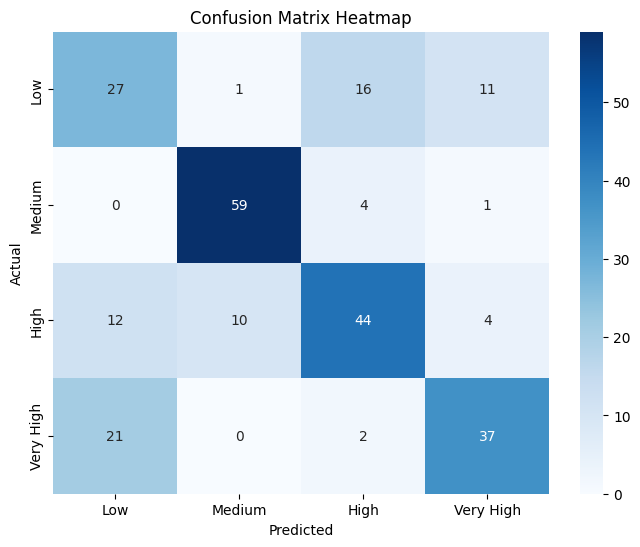

In [18]:
# visualizing the confusion matrix
plt.figure(figsize=(8,6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', 
            xticklabels=['Low', 'Medium', 'High', 'Very High'], 
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix Heatmap')
plt.show()

#### RANDOM FOREST

In [19]:
from sklearn.ensemble import RandomForestClassifier
# initializing random fores classifier using 100 trees
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Training the Model
rf_model.fit(x_train, y_train)

RandomForestClassifier(random_state=42)

In [20]:
# evaluating Accuracy
rf_pred = rf_model.predict(x_test)
rf_accuracy = accuracy_score(y_test, rf_pred)

print(f"Random Forest Accuracy: {rf_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test, rf_pred))

Random Forest Accuracy: 71.49%

Classification Report:
              precision    recall  f1-score   support

        High       0.54      0.56      0.55        55
         Low       0.83      0.92      0.87        64
      Medium       0.67      0.61      0.64        70
   Very High       0.79      0.75      0.77        60

    accuracy                           0.71       249
   macro avg       0.71      0.71      0.71       249
weighted avg       0.71      0.71      0.71       249



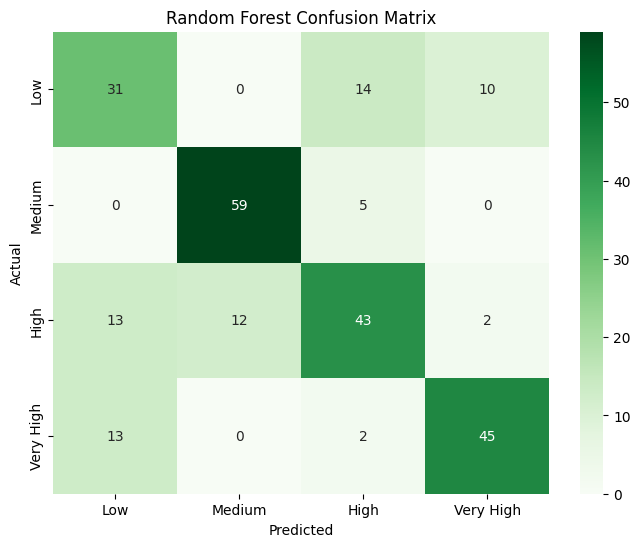

In [21]:
rf_conf_matrix = confusion_matrix(y_test, rf_pred)
plt.figure(figsize=(8,6))
sns.heatmap(rf_conf_matrix, annot=True, fmt='d', cmap='Greens',
            xticklabels=['Low', 'Medium', 'High', 'Very High'],
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Random Forest Confusion Matrix')
plt.show()


In [22]:
# performing hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV
param_dist = {
    'n_estimators': [100, 200, 300],
    'max_depth': [None, 10, 20, 30],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}
# Initializing the RandomizedSearchCV
rf_random = RandomizedSearchCV(estimator=RandomForestClassifier(random_state=42),
                               param_distributions=param_dist,
                               n_iter=10, cv=3, verbose=0, random_state=42, n_jobs=-1)

rf_random.fit(x_train, y_train)
print("Best Parameters Found:", rf_random.best_params_)

Best Parameters Found: {'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_depth': None}


In [23]:
# Evaluating the best model
best_rf_model = rf_random.best_estimator_
best_rf_pred = best_rf_model.predict(x_test)
best_rf_accuracy = accuracy_score(y_test, best_rf_pred)
print(f"Tuned Random Forest Accuracy: {best_rf_accuracy * 100:.2f}%")

Tuned Random Forest Accuracy: 69.08%


In [24]:
print("\nClassification Report:")
print(classification_report(y_test, best_rf_pred))


Classification Report:
              precision    recall  f1-score   support

        High       0.52      0.56      0.54        55
         Low       0.79      0.94      0.86        64
      Medium       0.69      0.53      0.60        70
   Very High       0.75      0.73      0.74        60

    accuracy                           0.69       249
   macro avg       0.68      0.69      0.68       249
weighted avg       0.69      0.69      0.69       249



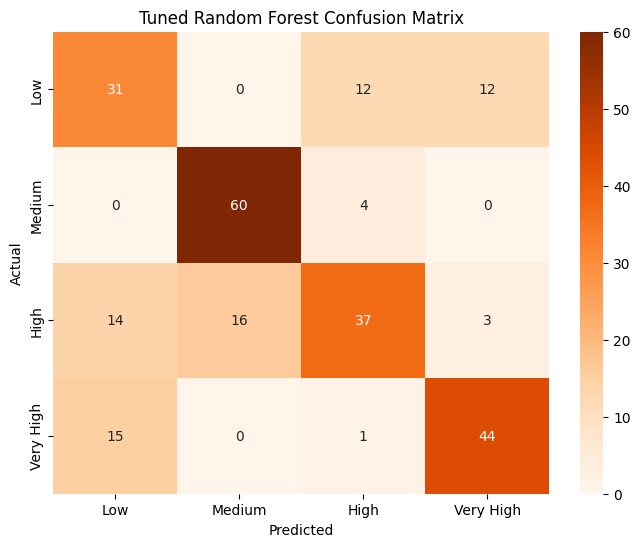

In [25]:
# Evaluating the  model
best_rf_conf_matrix = confusion_matrix(y_test, best_rf_pred)
plt.figure(figsize=(8,6))
sns.heatmap(best_rf_conf_matrix, annot=True, fmt='d', cmap='Oranges',
            xticklabels=['Low', 'Medium', 'High', 'Very High'],
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Random Forest Confusion Matrix')
plt.show()

even though after tuning the accuracy reduced the model performs better with the medim category prediction than the initial random forest model

In [26]:
# hyperparamter tuning--random forest

param_dist_advanced = {
    'n_estimators': [200, 300, 400, 500],
    'max_depth': [None, 10, 20, 30, 40, 50],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'bootstrap': [True, False]
}

rf_random_advanced = RandomizedSearchCV(estimator=RandomForestClassifier(random_state=42),
                                        param_distributions=param_dist_advanced,
                                        n_iter=50, cv=3, verbose=0, random_state=42, n_jobs=-1)
rf_random_advanced.fit(x_train, y_train)



RandomizedSearchCV(cv=3, estimator=RandomForestClassifier(random_state=42),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'bootstrap': [True, False],
                                        'max_depth': [None, 10, 20, 30, 40, 50],
                                        'min_samples_leaf': [1, 2, 4],
                                        'min_samples_split': [2, 5, 10],
                                        'n_estimators': [200, 300, 400, 500]},
                   random_state=42)

In [27]:
# Evaluating the new best model
final_rf_model = rf_random_advanced.best_estimator_
final_rf_pred = final_rf_model.predict(x_test)
final_rf_accuracy = accuracy_score(y_test, final_rf_pred)
print("Best Parameters :", rf_random_advanced.best_params_)
print(f"Tuned RF Accuracy: {final_rf_accuracy * 100:.2f}%")

Best Parameters : {'n_estimators': 500, 'min_samples_split': 5, 'min_samples_leaf': 2, 'max_depth': 10, 'bootstrap': True}
Tuned RF Accuracy: 69.08%


In [28]:
print("\nClassification Report:")
print(classification_report(y_test, final_rf_pred))


Classification Report:
              precision    recall  f1-score   support

        High       0.52      0.55      0.53        55
         Low       0.80      0.92      0.86        64
      Medium       0.68      0.54      0.60        70
   Very High       0.74      0.75      0.74        60

    accuracy                           0.69       249
   macro avg       0.68      0.69      0.68       249
weighted avg       0.69      0.69      0.69       249



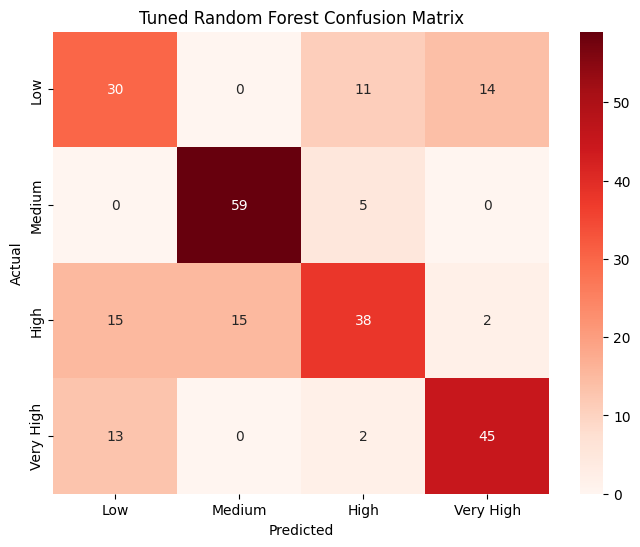

In [29]:
# Evaluating the  model
final_rf_conf_matrix = confusion_matrix(y_test, final_rf_pred)
plt.figure(figsize=(8,6))
sns.heatmap(final_rf_conf_matrix, annot=True, fmt='d', cmap='Reds',
            xticklabels=['Low', 'Medium', 'High', 'Very High'],
            yticklabels=['Low', 'Medium', 'High', 'Very High'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned Random Forest Confusion Matrix')
plt.show()

#### XG BOOST

In [30]:
import xgboost as xgb
from sklearn.preprocessing import LabelEncoder

In [31]:
# since xgboost needs numeric data, we need to encode the target variable
le = LabelEncoder()
y_encoded = le.fit_transform(y)

In [32]:
# resplitting data with encoded targets
x_train_xgb, x_test_xgb, y_train_xgb, y_test_xgb = train_test_split(x, y_encoded, test_size=0.2, random_state=42)

In [33]:
# training the model
xgb_model = xgb.XGBClassifier(use_label_encoder=False, eval_metric='mlogloss', random_state=42)
xgb_model.fit(x_train_xgb, y_train_xgb)

C:\Users\BerniceBoateng\AppData\Roaming\Python\Python312\site-packages\xgboost\core.py:158: UserWarning: [11:40:58] WARNING: C:\buildkite-agent\builds\buildkite-windows-cpu-autoscaling-group-i-08cbc0333d8d4aae1-1\xgboost\xgboost-ci-windows\src\learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='mlogloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=None, num_parallel_tree=None, objective='multi:softprob', ...)

In [34]:
# evaluating the model
xgb_pred = xgb_model.predict(x_test_xgb)
xgb_accuracy = accuracy_score(y_test_xgb, xgb_pred)
print(f"XGBoost Accuracy: {xgb_accuracy * 100:.2f}%")

XGBoost Accuracy: 73.49%


In [35]:
print("\nClassification Report:")
print(classification_report(y_test_xgb, xgb_pred))


Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.51      0.52        55
           1       0.91      0.91      0.91        64
           2       0.70      0.80      0.75        70
           3       0.79      0.68      0.73        60

    accuracy                           0.73       249
   macro avg       0.73      0.72      0.73       249
weighted avg       0.74      0.73      0.73       249



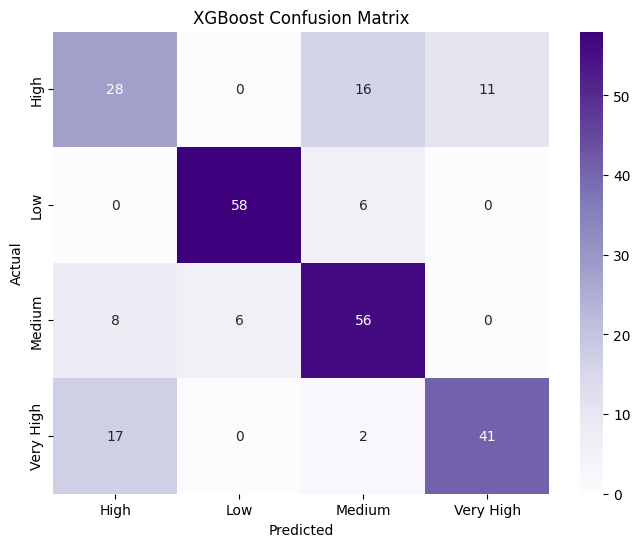

In [36]:
# Visualizing confusion matrix 
xgb_conf_matrix = confusion_matrix(y_test_xgb, xgb_pred)
plt.figure(figsize=(8,6))
sns.heatmap(xgb_conf_matrix, annot=True, fmt='d', cmap='Purples',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('XGBoost Confusion Matrix')
plt.show()

In [37]:
# hyperparameter tuning
from sklearn.model_selection import RandomizedSearchCV

xgb_param_grid = {
    'n_estimators': [100, 200, 300, 400],
    'learning_rate': [0.01, 0.05, 0.1, 0.2],
    'max_depth': [3, 4, 5, 6, 8, 10],
    'subsample': [0.6, 0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.6, 0.7, 0.8, 0.9, 1.0],
    'gamma': [0, 0.1, 0.2, 0.5]
}

xgb_random = RandomizedSearchCV(estimator=xgb.XGBClassifier(eval_metric='mlogloss', random_state=42),
                                param_distributions=xgb_param_grid,
                                n_iter=50, cv=3, verbose=1, random_state=42, n_jobs=-1)

In [38]:
# evaluating the model
xgb_random.fit(x_train_xgb, y_train_xgb)
print(f"Best Parameters Found: {xgb_random.best_params_}")
best_xgb_model = xgb_random.best_estimator_

tuned_xgb_pred = best_xgb_model.predict(x_test_xgb)
tuned_xgb_accuracy = accuracy_score(y_test_xgb, tuned_xgb_pred)

print(f"Tuned XGBoost Accuracy: {tuned_xgb_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test_xgb, tuned_xgb_pred))


Fitting 3 folds for each of 50 candidates, totalling 150 fits
Best Parameters Found: {'subsample': 0.6, 'n_estimators': 100, 'max_depth': 4, 'learning_rate': 0.2, 'gamma': 0.1, 'colsample_bytree': 0.6}
Tuned XGBoost Accuracy: 73.09%

Classification Report:
              precision    recall  f1-score   support

           0       0.53      0.56      0.55        55
           1       0.88      0.91      0.89        64
           2       0.69      0.74      0.72        70
           3       0.82      0.68      0.75        60

    accuracy                           0.73       249
   macro avg       0.73      0.72      0.73       249
weighted avg       0.74      0.73      0.73       249



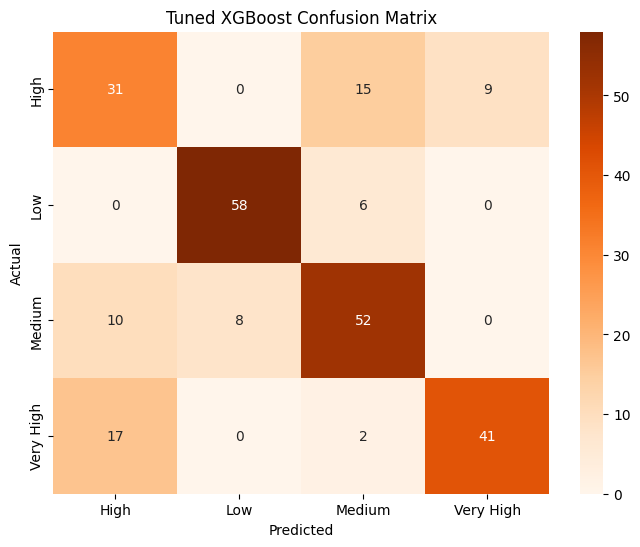

In [39]:
# visualizing the model
tuned_xgb_conf = confusion_matrix(y_test_xgb, tuned_xgb_pred)
plt.figure(figsize=(8,6))
sns.heatmap(tuned_xgb_conf, annot=True, fmt='d', cmap='Oranges',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Tuned XGBoost Confusion Matrix')
plt.show()

#### Ensembling the three best models

Decision Tree: default (69.08%)

Random Forest: default (71.49%)

XGBoost: default (73.49%)

In [40]:
# creating an ensemble model using the best performing classifiers
from sklearn.ensemble import VotingClassifier
import joblib

# re-initializing the best models (default parameters were best for all)
dt_best = DecisionTreeClassifier(random_state=42)
rf_best = RandomForestClassifier(n_estimators=100, random_state=42)
xgb_best = xgb.XGBClassifier(eval_metric='mlogloss', random_state=42)

In [41]:
# training ensemble model
ensemble_model = VotingClassifier(
    estimators=[('dt', dt_best), ('rf', rf_best), ('xgb', xgb_best)],
    voting='soft'
)

ensemble_model.fit(x_train_xgb, y_train_xgb)
print("Ensemble model trained successfully!")

Ensemble model trained successfully!


In [42]:
# evaluating ensemble model
ensemble_pred = ensemble_model.predict(x_test_xgb)
ensemble_accuracy = accuracy_score(y_test_xgb, ensemble_pred)

print(f"Ensemble Accuracy: {ensemble_accuracy * 100:.2f}%")
print(f"Default XGBoost Accuracy: {xgb_accuracy * 100:.2f}%")

Ensemble Accuracy: 70.28%
Default XGBoost Accuracy: 73.49%


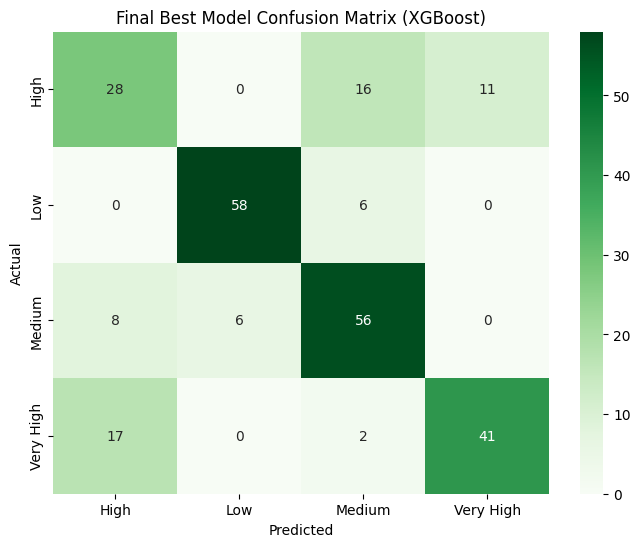

In [45]:
# visualizing confusion matrix for final model
# using xgb_pred since xgboost won and it was already evaluated earlier
final_conf = confusion_matrix(y_test_xgb, xgb_pred)

plt.figure(figsize=(8,6))
sns.heatmap(final_conf, annot=True, fmt='d', cmap='Greens',
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Final Best Model Confusion Matrix (XGBoost)')
plt.show()

In [46]:
# selecting and saving the best model
if ensemble_accuracy > xgb_accuracy:
    print("\nEnsemble wins! Saving ensemble model...")
    final_model = ensemble_model
    final_name = 'ensemble_model.pkl'
else:
    print("\nXGBoost wins! Saving xgboost model...")
    final_model = xgb_model  
    final_name = 'xgboost_model.pkl'

joblib.dump(final_model, final_name)
joblib.dump(le, 'label_encoder.pkl')
print(f"Model saved as '{final_name}' and Label Encoder saved as 'label_encoder.pkl'")


XGBoost wins! Saving xgboost model...
Model saved as 'xgboost_model.pkl' and Label Encoder saved as 'label_encoder.pkl'


#### Manual testing

In [50]:
# manual prediction interface
def predict_laptop_price(laptop_features):
    # loading the saved model and label encoder
    import joblib
    model = joblib.load('xgboost_model.pkl')
    label_encoder = joblib.load('label_encoder.pkl')
    
    # creating a dataframe from the input
    input_df = pd.DataFrame([laptop_features])
    
    # one-hot encoding categorical features (same as training)
    categorical_cols = input_df.select_dtypes(include=['object']).columns
    input_encoded = pd.get_dummies(input_df, columns=categorical_cols, drop_first=True)
    
    # aligning columns with training data (adding missing columns as 0)
    missing_cols = set(x.columns) - set(input_encoded.columns)
    for col in missing_cols:
        input_encoded[col] = 0
    
    # reordering columns to match training data
    input_encoded = input_encoded[x.columns]
    
    # making prediction
    prediction = model.predict(input_encoded)
    
    # converting back to category name
    category = label_encoder.inverse_transform(prediction)
    
    return category[0]

In [56]:
import warnings
warnings.filterwarnings('ignore')

In [57]:
# testing laptop 1 below - actual: High
laptop_1 = {
    'company': 'apple', 'typename': 'ultrabook', 'inches': 13.3, 'ram': 8, 'weight': 1.37,
    'screen_type': 'ips panel retina display', 'screen_width': 2560, 'screen_height': 1600,
    'touchscreen': 0, 'cpu_name': 'intel core i5', 'cpu_brand': 'intel core i5', 'cpu_speed': 2.3,
    'hdd': 0, 'ssd': 128, 'hybrid': 0, 'flash_storage': 0, 'gpu_brand': 'intel iris', 'operating_system': 'mac'
}
print(f"Laptop 1 - Predicted: {predict_laptop_price(laptop_1)}, Actual: High")

Laptop 1 - Predicted: High, Actual: High


In [58]:
# testing laptop 2 - actual: Medium
laptop_2 = {
    'company': 'apple', 'typename': 'ultrabook', 'inches': 13.3, 'ram': 8, 'weight': 1.34,
    'screen_type': 'standard', 'screen_width': 1440, 'screen_height': 900,
    'touchscreen': 0, 'cpu_name': 'intel core i5', 'cpu_brand': 'intel core i5', 'cpu_speed': 1.8,
    'hdd': 0, 'ssd': 0, 'hybrid': 0, 'flash_storage': 128, 'gpu_brand': 'intel hd', 'operating_system': 'mac'
}
print(f"Laptop 2 - Predicted: {predict_laptop_price(laptop_2)}, Actual: Medium")

Laptop 2 - Predicted: Medium, Actual: Medium


In [59]:
# test laptop 3 - actual: Low
laptop_3 = {
    'company': 'hp', 'typename': 'notebook', 'inches': 15.6, 'ram': 8, 'weight': 1.86,
    'screen_type': 'full hd', 'screen_width': 1920, 'screen_height': 1080,
    'touchscreen': 0, 'cpu_name': 'intel core i5', 'cpu_brand': 'intel core i5', 'cpu_speed': 2.5,
    'hdd': 0, 'ssd': 256, 'hybrid': 0, 'flash_storage': 0, 'gpu_brand': 'intel hd', 'operating_system': 'others/no os'
}
print(f"Laptop 3 - Predicted: {predict_laptop_price(laptop_3)}, Actual: Low")

Laptop 3 - Predicted: Medium, Actual: Low


In [60]:
# testing laptop 4 - actual: Very High
laptop_4 = {
    'company': 'apple', 'typename': 'ultrabook', 'inches': 15.4, 'ram': 16, 'weight': 1.83,
    'screen_type': 'ips panel retina display', 'screen_width': 2880, 'screen_height': 1800,
    'touchscreen': 0, 'cpu_name': 'intel core i7', 'cpu_brand': 'intel core i7', 'cpu_speed': 2.7,
    'hdd': 0, 'ssd': 512, 'hybrid': 0, 'flash_storage': 0, 'gpu_brand': 'amd radeon', 'operating_system': 'mac'
}
print(f"Laptop 4 - Predicted: {predict_laptop_price(laptop_4)}, Actual: Very High")

Laptop 4 - Predicted: Very High, Actual: Very High


In [61]:
# testing laptop 5 - actual: Very High
laptop_5 = {
    'company': 'apple', 'typename': 'ultrabook', 'inches': 13.3, 'ram': 8, 'weight': 1.37,
    'screen_type': 'ips panel retina display', 'screen_width': 2560, 'screen_height': 1600,
    'touchscreen': 0, 'cpu_name': 'intel core i5', 'cpu_brand': 'intel core i5', 'cpu_speed': 3.1,
    'hdd': 0, 'ssd': 256, 'hybrid': 0, 'flash_storage': 0, 'gpu_brand': 'intel iris', 'operating_system': 'mac'
}
print(f"Laptop 5 - Predicted: {predict_laptop_price(laptop_5)}, Actual: Very High")

Laptop 5 - Predicted: Very High, Actual: Very High


In [48]:
laptops.head(5)

,company,typename,inches,ram,weight,price,screen_type,screen_width,screen_height,touchscreen,cpu_name,cpu_brand,cpu_speed,hdd,ssd,hybrid,flash_storage,gpu_brand,operating_system,price_category
0,apple,ultrabook,13.3,8,1.37,71378.6832,ips panel retina display,2560,1600,0,intel core i5,intel core i5,2.3,0,128,0,0,intel iris,mac,High
1,apple,ultrabook,13.3,8,1.34,47895.5232,standard,1440,900,0,intel core i5,intel core i5,1.8,0,0,0,128,intel hd,mac,Medium
2,hp,notebook,15.6,8,1.86,30636.0000,full hd,1920,1080,0,intel core i5,intel core i5,2.5,0,256,0,0,intel hd,others/no os,Low
3,apple,ultrabook,15.4,16,1.83,135195.3360,ips panel retina display,2880,1800,0,intel core i7,intel core i7,2.7,0,512,0,0,amd radeon,mac,Very High
4,apple,ultrabook,13.3,8,1.37,96095.8080,ips panel retina display,2560,1600,0,intel core i5,intel core i5,3.1,0,256,0,0,intel iris,mac,Very High
